# Prova Prática — Ciência de Dados com Python

**Nome:** Laryssa Mota de Sousa  **Data:** 30/10/2026

## Instruções
1. Baixe o arquivo **vendas_loja.csv** e faça upload no Google Colab (ícone de pasta 📁 na barra lateral).
2. Resolva as **10 questões** nas células indicadas, escrevendo seu código.
3. O notebook deve rodar do início ao fim sem erros (use **Runtime → Run all** antes de entregar).
4. Cada questão vale **1,0 ponto**.

## Dataset: vendas_loja.csv
Registros de vendas de uma loja de eletrônicos, com as colunas:
`produto`, `categoria`, `preco`, `quantidade`, `vendedor`, `regiao`, `mes`

> ⚠️ Atenção: o dataset contém **valores ausentes e linhas duplicadas de propósito** — você vai precisar tratá-los nas questões 4 e 5!


In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Questão 1 — Importação e exploração (1,0 pt)
Importe o arquivo `vendas_loja.csv` e mostre:
- as 5 primeiras linhas (`head`)
- o tamanho do dataset (`shape`)
- as informações gerais (`info`)

In [107]:
# Q1 - seu código aqui
df = pd.read_csv('vendas_loja.csv')

df.head()


,produto,categoria,preco,quantidade,vendedor,regiao,mes
0,Caixa de Som,Áudio,110.0,10.0,Carla,Leste,Abr
1,Monitor,Informática,900.0,10.0,Carla,Oeste,Abr
2,Cabo HDMI,Acessórios,30.0,3.0,Diego,Sul,Fev
3,Webcam,Informática,150.0,7.0,Ana,Norte,Mar
4,Caixa de Som,Áudio,110.0,1.0,Diego,Oeste,Abr


In [108]:
df.shape


(122, 7)

In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   produto     122 non-null    object 
 1   categoria   122 non-null    object 
 2   preco       118 non-null    float64
 3   quantidade  116 non-null    float64
 4   vendedor    122 non-null    object 
 5   regiao      122 non-null    object 
 6   mes         122 non-null    object 
dtypes: float64(2), object(5)
memory usage: 6.8+ KB


## Questão 2 — Explorando com describe (1,0 pt)
Mostre as estatísticas das colunas numéricas com `describe()` e escreva **uma frase** interpretando qual é a média de `preco` do dataset.

In [110]:
# Q2 - seu código aqui
df.describe()

# O 'describe()' trouxe vários valores, dentre eles a média de preço, que é a soma dos valores, divido pela quantidade.

,preco,quantidade
count,118.000000,116.000000
mean,175.805085,5.267241
std,239.386654,2.979226
min,25.000000,1.000000
25%,40.000000,3.000000
50%,110.000000,5.000000
75%,150.000000,8.000000
max,900.000000,10.000000


## Questão 3 — NumPy (1,0 pt)
Transforme a coluna `preco` em um array NumPy e calcule e imprima:
- a média
- o maior preço
- o menor preço
- a quantidade de preços registrados (`size`)

In [111]:
# Q3 - seu código aqui
array = df['preco'].to_numpy()

In [112]:
print(array.mean())
print(array.max())
print(array.min())
print(array.size)


nan
nan
nan
122


## Questão 4 — Valores ausentes (1,0 pt)
a) Conte quantos valores ausentes existem em **cada coluna**.
b) Preencha os ausentes de `preco` com a **média** da coluna e os de `quantidade` com o valor **0**.
c) Mostre de novo a contagem de ausentes para provar que não sobrou nenhum.
> Justifique em uma frase: por que preencher `quantidade` com 0 e não com a média?

 R: Para nao interferir nos outros valores, quando for fazer uma operação

In [113]:
# Q4 - seu código aqui
print(df.isnull().sum())

produto       0
categoria     0
preco         4
quantidade    6
vendedor      0
regiao        0
mes           0
dtype: int64


In [114]:
df["preco"] = df["preco"].fillna(df["preco"].mean())


In [115]:
df["quantidade"] = df["quantidade"].fillna(df["quantidade"] == 0)


In [116]:
print(df.isnull().sum())

produto       0
categoria     0
preco         0
quantidade    0
vendedor      0
regiao        0
mes           0
dtype: int64


## Questão 5 — Duplicados (1,0 pt)
Verifique quantas linhas duplicadas existem no DataFrame e remova-as, mantendo a primeira ocorrência. Mostre o `shape` antes e depois.

In [117]:
# Q5 - seu código aqui
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
117,False
118,False
119,False
120,True


In [118]:
df.drop_duplicates()

,produto,categoria,preco,quantidade,vendedor,regiao,mes
0,Caixa de Som,Áudio,110.000000,10.0,Carla,Leste,Abr
1,Monitor,Informática,900.000000,10.0,Carla,Oeste,Abr
2,Cabo HDMI,Acessórios,30.000000,3.0,Diego,Sul,Fev
3,Webcam,Informática,150.000000,7.0,Ana,Norte,Mar
4,Caixa de Som,Áudio,110.000000,1.0,Diego,Oeste,Abr
...,...,...,...,...,...,...,...
115,Webcam,Informática,150.000000,5.0,Elisa,Norte,Fev
116,HD Externo,Armazenamento,350.000000,7.0,Diego,Oeste,Fev
117,Caixa de Som,Áudio,110.000000,9.0,Diego,Oeste,Abr
118,Caixa de Som,Áudio,110.000000,9.0,Diego,Oeste,Jan


In [119]:
df.shape

(122, 7)

## Questão 6 — Criando coluna calculada (1,0 pt)
Crie a coluna `total`, que deve ser `preco` × `quantidade` (valor total de cada venda). Mostre o DataFrame com as colunas `produto`, `preco`, `quantidade` e `total`.

In [120]:
# Q6 - seu código aqui
df["total"] = df["preco"] * df["quantidade"]

In [121]:
df[['produto','preco', 'quantidade', 'total']]

,produto,preco,quantidade,total
0,Caixa de Som,110.000000,10.0,1100.0
1,Monitor,900.000000,10.0,9000.0
2,Cabo HDMI,30.000000,3.0,90.0
3,Webcam,150.000000,7.0,1050.0
4,Caixa de Som,110.000000,1.0,110.0
...,...,...,...,...
117,Caixa de Som,110.000000,9.0,990.0
118,Caixa de Som,110.000000,9.0,990.0
119,Pen Drive,175.805085,3.0,527.415254
120,Monitor,900.000000,4.0,3600.0


## Questão 7 — Filtros com condição (1,0 pt)
Filtre e mostre apenas as vendas cujo `total` seja **maior ou igual a 500**. Quantas vendas são essas?

In [122]:
# Q7 - seu código aqui
filtro = df[df["total"] >= 500]

In [123]:
print(filtro)

          produto      categoria       preco quantidade vendedor regiao  mes  \
0    Caixa de Som          Áudio  110.000000       10.0    Carla  Leste  Abr   
1         Monitor    Informática  900.000000       10.0    Carla  Oeste  Abr   
3          Webcam    Informática  150.000000        7.0      Ana  Norte  Mar   
5      HD Externo  Armazenamento  350.000000        4.0    Carla  Oeste  Jan   
7    Caixa de Som          Áudio  110.000000        5.0    Diego  Leste  Mai   
9          Webcam    Informática  150.000000        7.0    Carla  Leste  Mar   
10        Monitor    Informática  900.000000        4.0      Ana  Oeste  Mai   
15         Webcam    Informática  150.000000       10.0    Bruno  Oeste  Fev   
16        Teclado    Informática  120.000000        9.0    Bruno    Sul  Mar   
20         Webcam    Informática  150.000000       10.0    Diego  Oeste  Abr   
22     HD Externo  Armazenamento  350.000000        9.0    Diego  Leste  Fev   
26     HD Externo  Armazenamento  350.00

## Questão 8 — Filtro com duas condições (1,0 pt)
Filtre e mostre as vendas da **região 'Sul'** com **quantidade maior que 5**. Use o operador `&` e não esqueça dos parênteses!
> Escreva o filtro na forma: `df[(condição1) & (condição2)]`

In [124]:
# Q8 - seu código aqui
filtro_2 = df[(df["regiao"] == 'Sul') & (df["quantidade"] > 5)]

print(filtro_2)

          produto      categoria       preco quantidade vendedor regiao  mes  \
16        Teclado    Informática  120.000000        9.0    Bruno    Sul  Mar   
26     HD Externo  Armazenamento  350.000000        9.0    Carla    Sul  Mar   
38        Teclado    Informática  120.000000       10.0      Ana    Sul  Fev   
41        Teclado    Informática  120.000000        8.0    Elisa    Sul  Mai   
69      Pen Drive     Acessórios  175.805085        7.0      Ana    Sul  Jan   
74      Cabo HDMI     Acessórios   30.000000        6.0    Bruno    Sul  Mai   
75     HD Externo  Armazenamento  350.000000        8.0    Carla    Sul  Mar   
82      Cabo HDMI     Acessórios   30.000000        9.0    Carla    Sul  Mar   
88      Cabo HDMI     Acessórios   30.000000       10.0      Ana    Sul  Mar   
92         Webcam    Informática  150.000000        7.0      Ana    Sul  Mar   
94   Caixa de Som          Áudio  110.000000        9.0    Elisa    Sul  Jan   
97   Caixa de Som          Áudio  110.00

## Questão 9 — Agrupamento com groupby (1,0 pt)
a) Use `groupby` para mostrar o **total vendido por categoria** (soma da coluna `total`).
b) Monte um resumo com `.agg()` mostrando, por categoria: soma das vendas, ticket médio e quantidade de vendas (use `reset_index()`).
c) Escreva **uma frase**: qual categoria vendeu mais?

In [125]:
# Q9 - seu código aqui
total_vendido = df.groupby('categoria')['total'].sum()
total_vendido

,total
categoria,
Acessórios,6858.050847
Armazenamento,21350.0
Informática,66820.0
Áudio,16814.491525


In [126]:
total_vendido_2 = df.groupby('categoria').agg(
    total_vendas = ('total', 'sum'),
    ticket_medio = ('total', 'mean'),
    quantidade_vendas = ('quantidade', 'count')
).reset_index()

total_vendido_2

,categoria,total_vendas,ticket_medio,quantidade_vendas
0,Acessórios,6858.050847,185.352726,37
1,Armazenamento,21350.0,1779.166667,12
2,Informática,66820.0,1484.888889,45
3,Áudio,16814.491525,600.517554,28


R: A categoria "Áudio" foi a que mais vendeu

## Questão 10 — Visualização (1,0 pt)
Crie **dois gráficos** e escreva uma frase interpretando cada um:
1. **Matplotlib**: gráfico de barras com o total vendido por categoria (com `title`, `xlabel` e `ylabel`).
2. **Seaborn**: `boxplot` da coluna `total` por `regiao` — existe alguma região com vendas fora da curva?

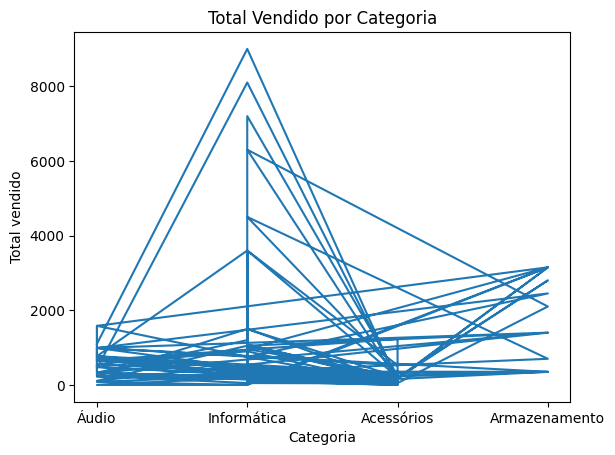

In [127]:
# Q10 - gráfico 1 (Matplotlib)

plt.plot(df['categoria'], df['total'])
plt.title('Total Vendido por Categoria')
plt.xlabel('Categoria')
plt.ylabel('Total vendido')
plt.show()

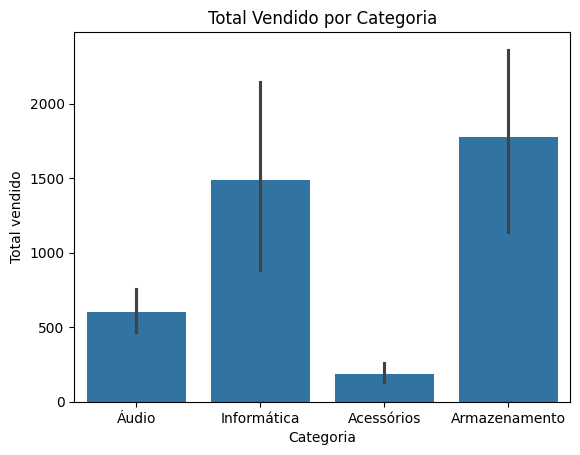

In [128]:
# Q10 - gráfico 2 (Seaborn)
sns.barplot(data=df, x='categoria', y= 'total')

plt.title('Total Vendido por Categoria')
plt.xlabel('Categoria')
plt.ylabel('Total vendido')
plt.show()

---
## Entrega
1. Rode tudo: **Runtime → Run all** e confira que não há erros.
2. Baixe o notebook: **File → Download → Download .ipynb**.
3. Envie o arquivo `.ipynb` pelo link indicado pelo professor.

**Boa prova! 🚀**